In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Machine Learning environment is ready!")

Matplotlib is building the font cache; this may take a moment.


Machine Learning environment is ready!


In [2]:
# Load the Bank Marketing dataset
df = pd.read_csv("../data/bank.csv", sep=";")

# Display the first 5 records
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (4521, 17)


In [4]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 600.6 KB


In [5]:
# Check missing values in each column
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [6]:
# Check the target variable distribution
print(df['y'].value_counts())

y
no     4000
yes     521
Name: count, dtype: int64


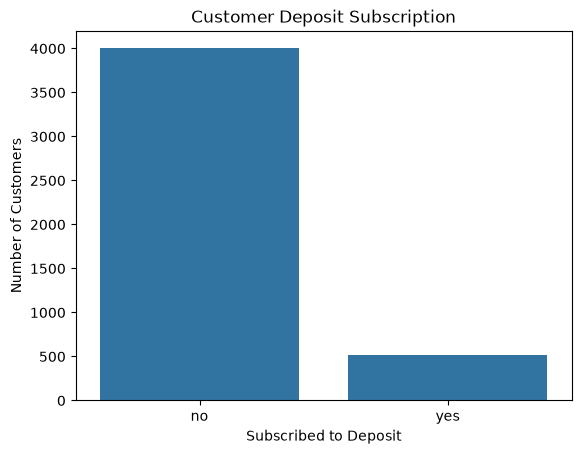

In [7]:
# Visualize the target variable distribution
sns.countplot(x='y', data=df)

plt.title("Customer Deposit Subscription")
plt.xlabel("Subscribed to Deposit")
plt.ylabel("Number of Customers")
plt.show()

In [8]:
# Separate input features and target variable

X = df.drop('y', axis=1)
y = df['y'].map({'no': 0, 'yes': 1})

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Input features shape: (4521, 16)
Target shape: (4521,)

Target values:
y
0    4000
1     521
Name: count, dtype: int64


In [9]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the number of records
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 3616
Testing records: 905


In [10]:
# Convert categorical columns into numerical columns

X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)

# Ensure both datasets have the same columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (3616, 51)
Testing data shape: (905, 51)


In [11]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train_encoded)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test_encoded)

# Check the shapes
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (3616, 51)
Scaled testing data: (905, 51)


In [12]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using training data
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Make predictions using Logistic Regression
lr_predictions = lr_model.predict(X_test_scaled)

# Display the first 10 predictions
print("Predicted values:", lr_predictions[:10])
print("Actual values:   ", y_test.values[:10])

Predicted values: [0 0 0 0 0 0 0 1 0 0]
Actual values:    [1 0 0 0 0 0 0 1 1 0]


In [14]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# Calculate model performance
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions, zero_division=0)
lr_recall = recall_score(y_test, lr_predictions, zero_division=0)
lr_f1 = f1_score(y_test, lr_predictions, zero_division=0)

# Display results
print("Logistic Regression Performance")
print("--------------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1-score :", round(lr_f1, 4))

Logistic Regression Performance
--------------------------------
Accuracy : 0.8917
Precision: 0.5536
Recall   : 0.2981
F1-score : 0.3875


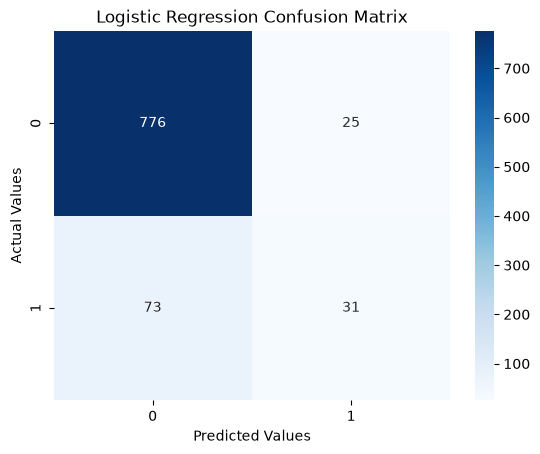

In [15]:
# Import confusion matrix
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
lr_cm = confusion_matrix(y_test, lr_predictions)

# Display confusion matrix
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues')

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()